# Phase 7 F1 — public repetition-penalty sweep

This privacy-safe notebook loads aggregate validation metrics and public plots. It contains no audio, manifests, IDs, prediction text, checkpoints, or test-set outputs.

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import Image, display

ROOT = Path('..')
metrics_path = ROOT / 'docs' / 'PHASE7_F1_REPETITION_PENALTY_SWEEP_AGGREGATE.json'
metrics = json.loads(metrics_path.read_text())
table = pd.DataFrame(metrics['results'])
display(table)
print({'selected_penalty': metrics['selected_repetition_penalty'], 'test_data_used': metrics['test_data_used']})

,repetition_penalty,corpus_cer_percent,S,D,I,edit_count,eos_count,cap_without_eos,mean_prediction_reference_length_ratio
0,1.00,51.346337,15940,4323,12669,32932,730,2,1.164961
1,1.02,50.886384,15290,4655,12692,32637,730,2,1.156840
2,1.05,48.549199,14785,5236,11117,31138,732,0,1.133413
3,1.08,48.391724,14542,5739,10756,31037,732,0,1.120386
4,1.10,48.485274,14513,6093,10491,31097,732,0,1.114297


{'selected_penalty': 1.08, 'test_data_used': False}


## Result

Penalty `1.08` is selected by the lowest corpus validation CER: **48.39172%** over all 732 validation clips. This remains a validation result; the 683-clip test set was not used.

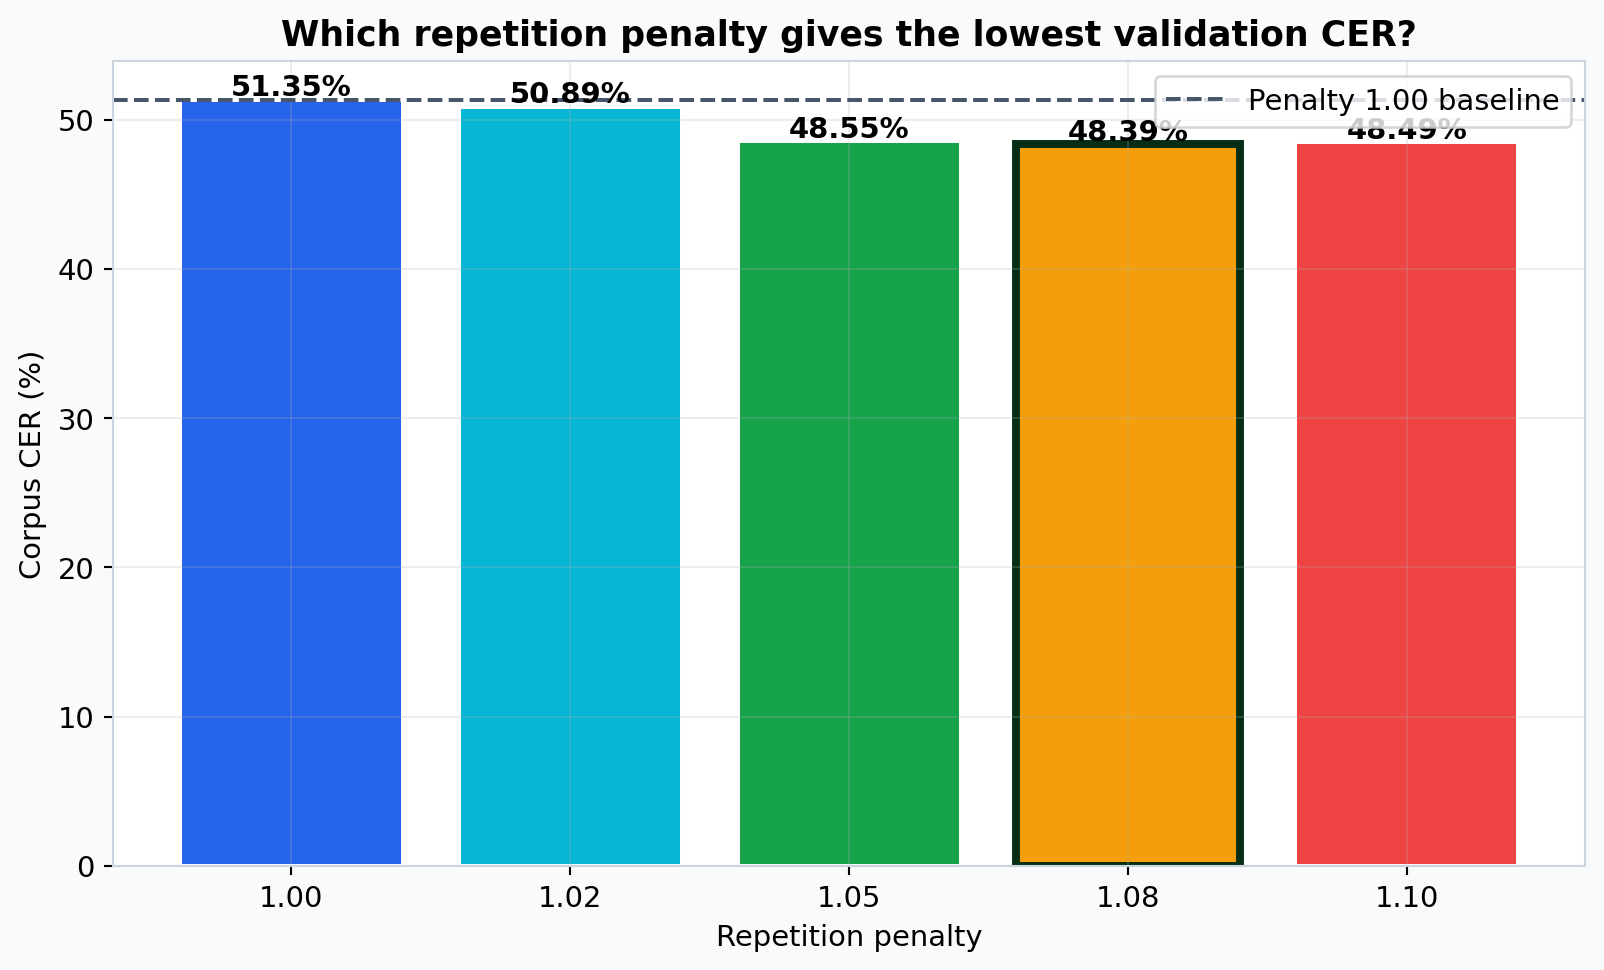

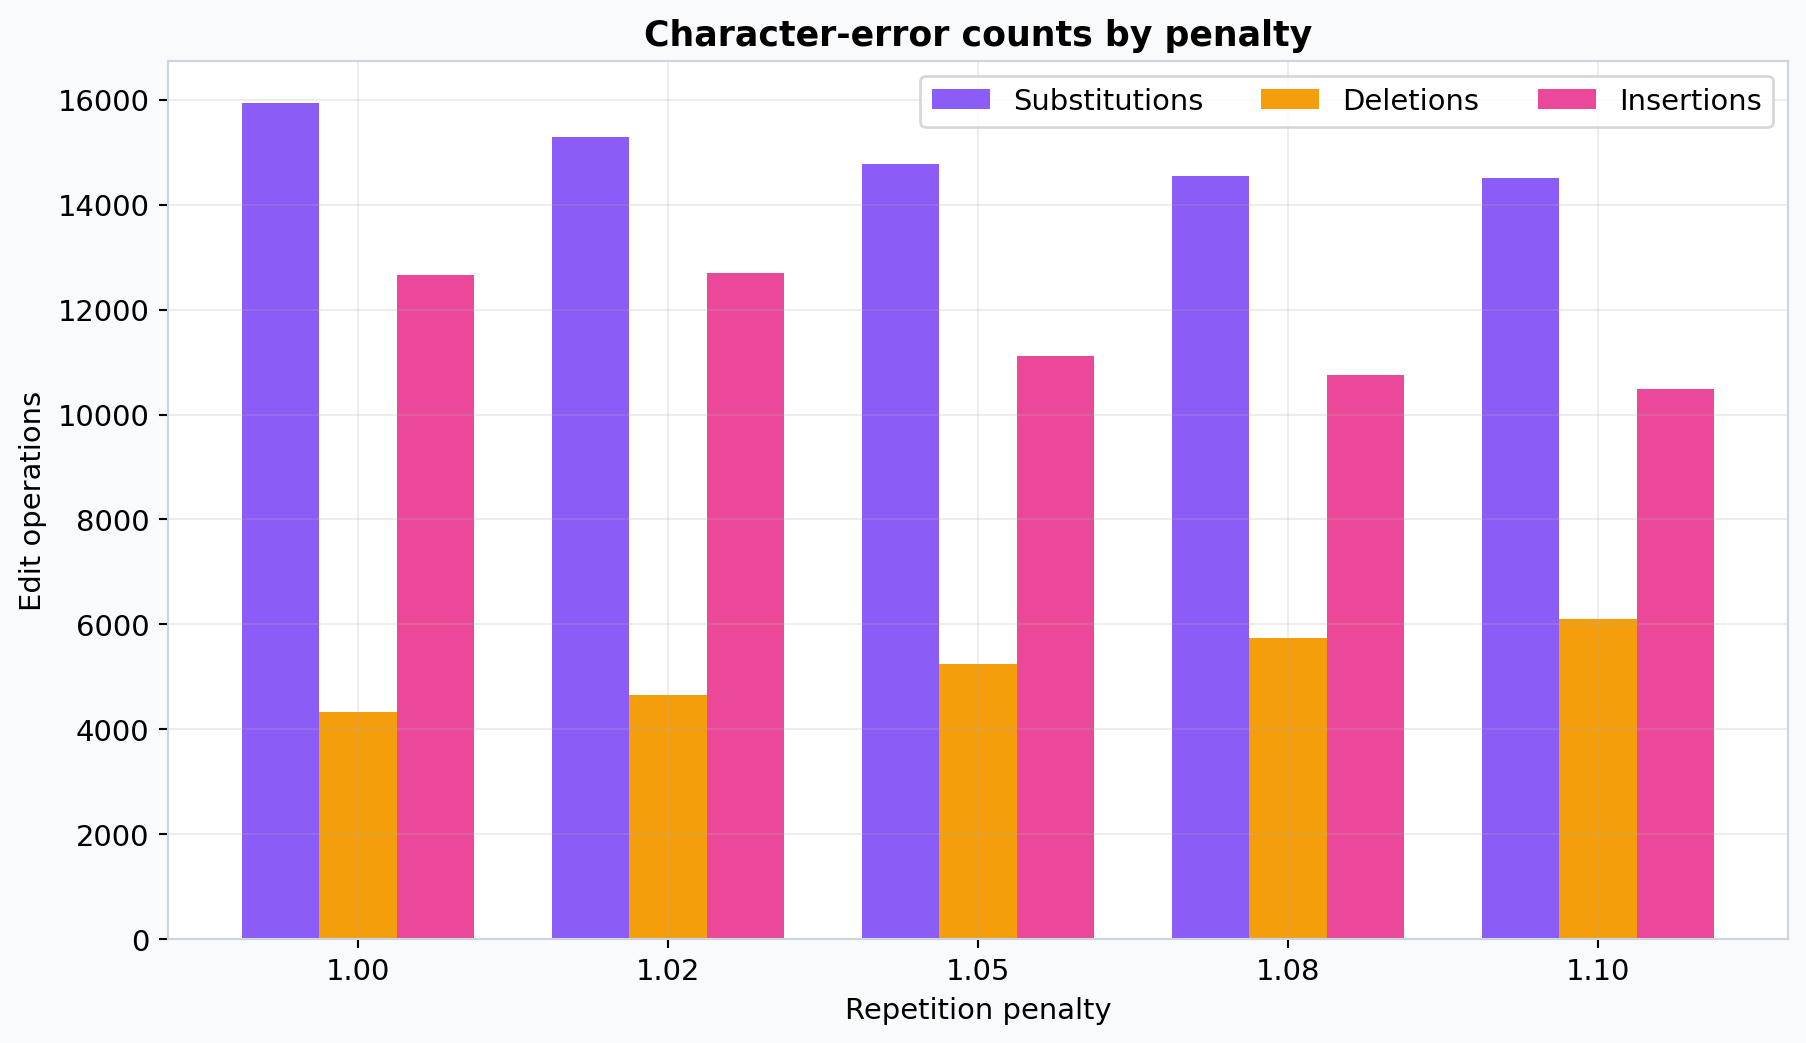

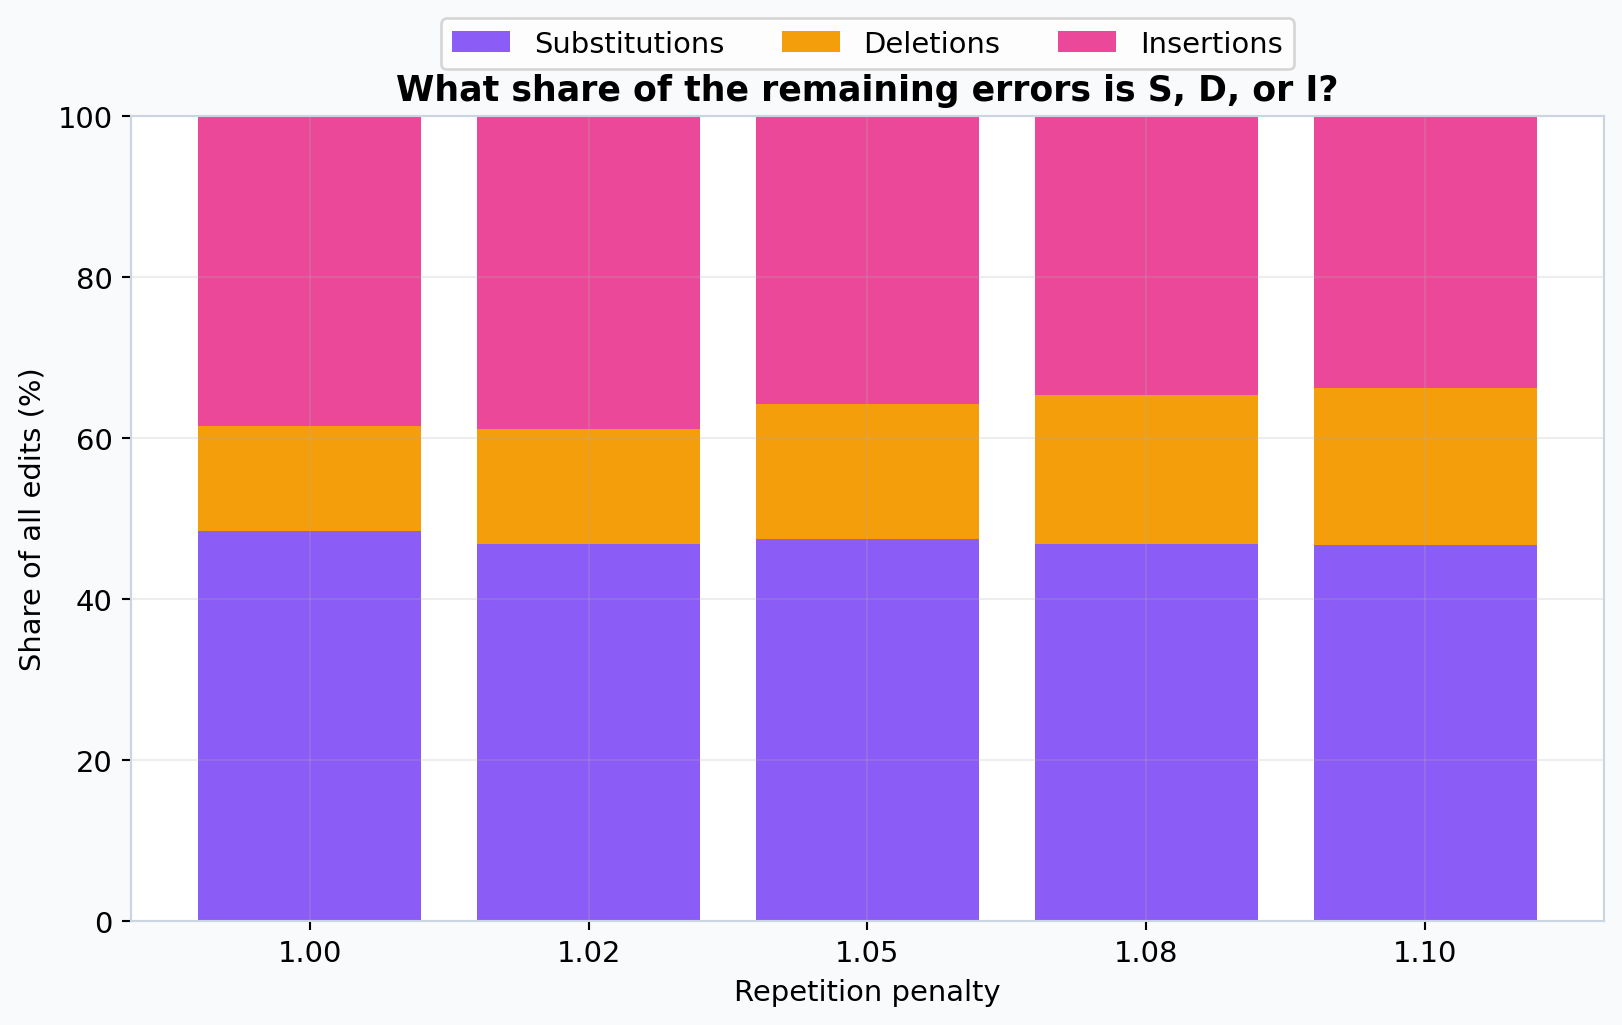

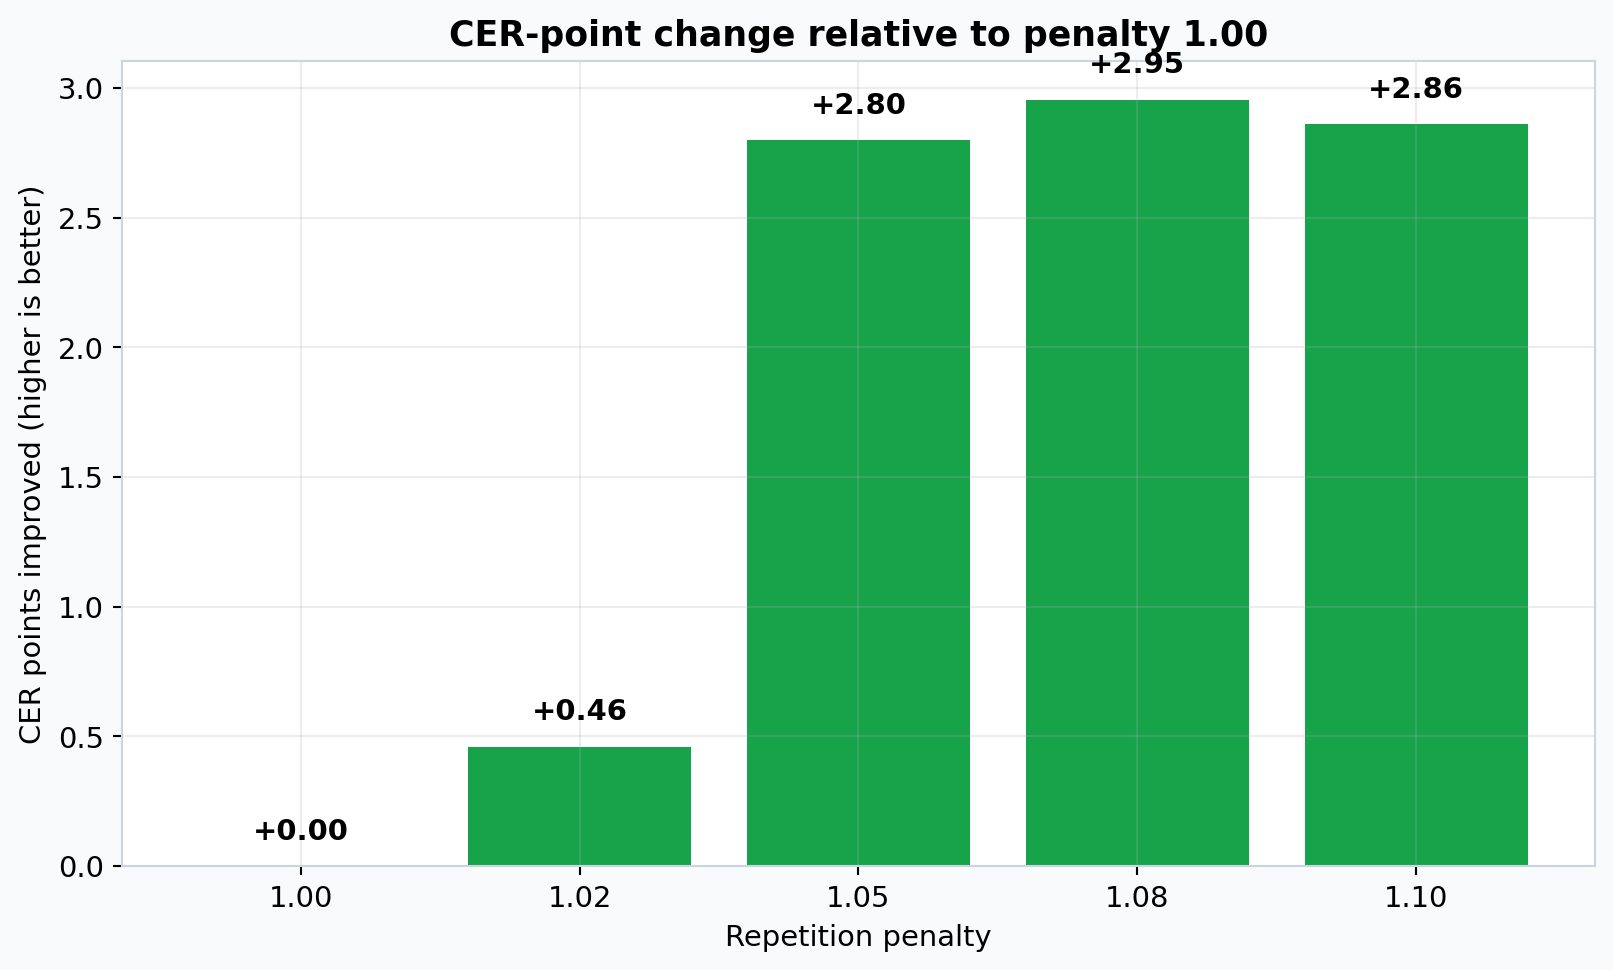

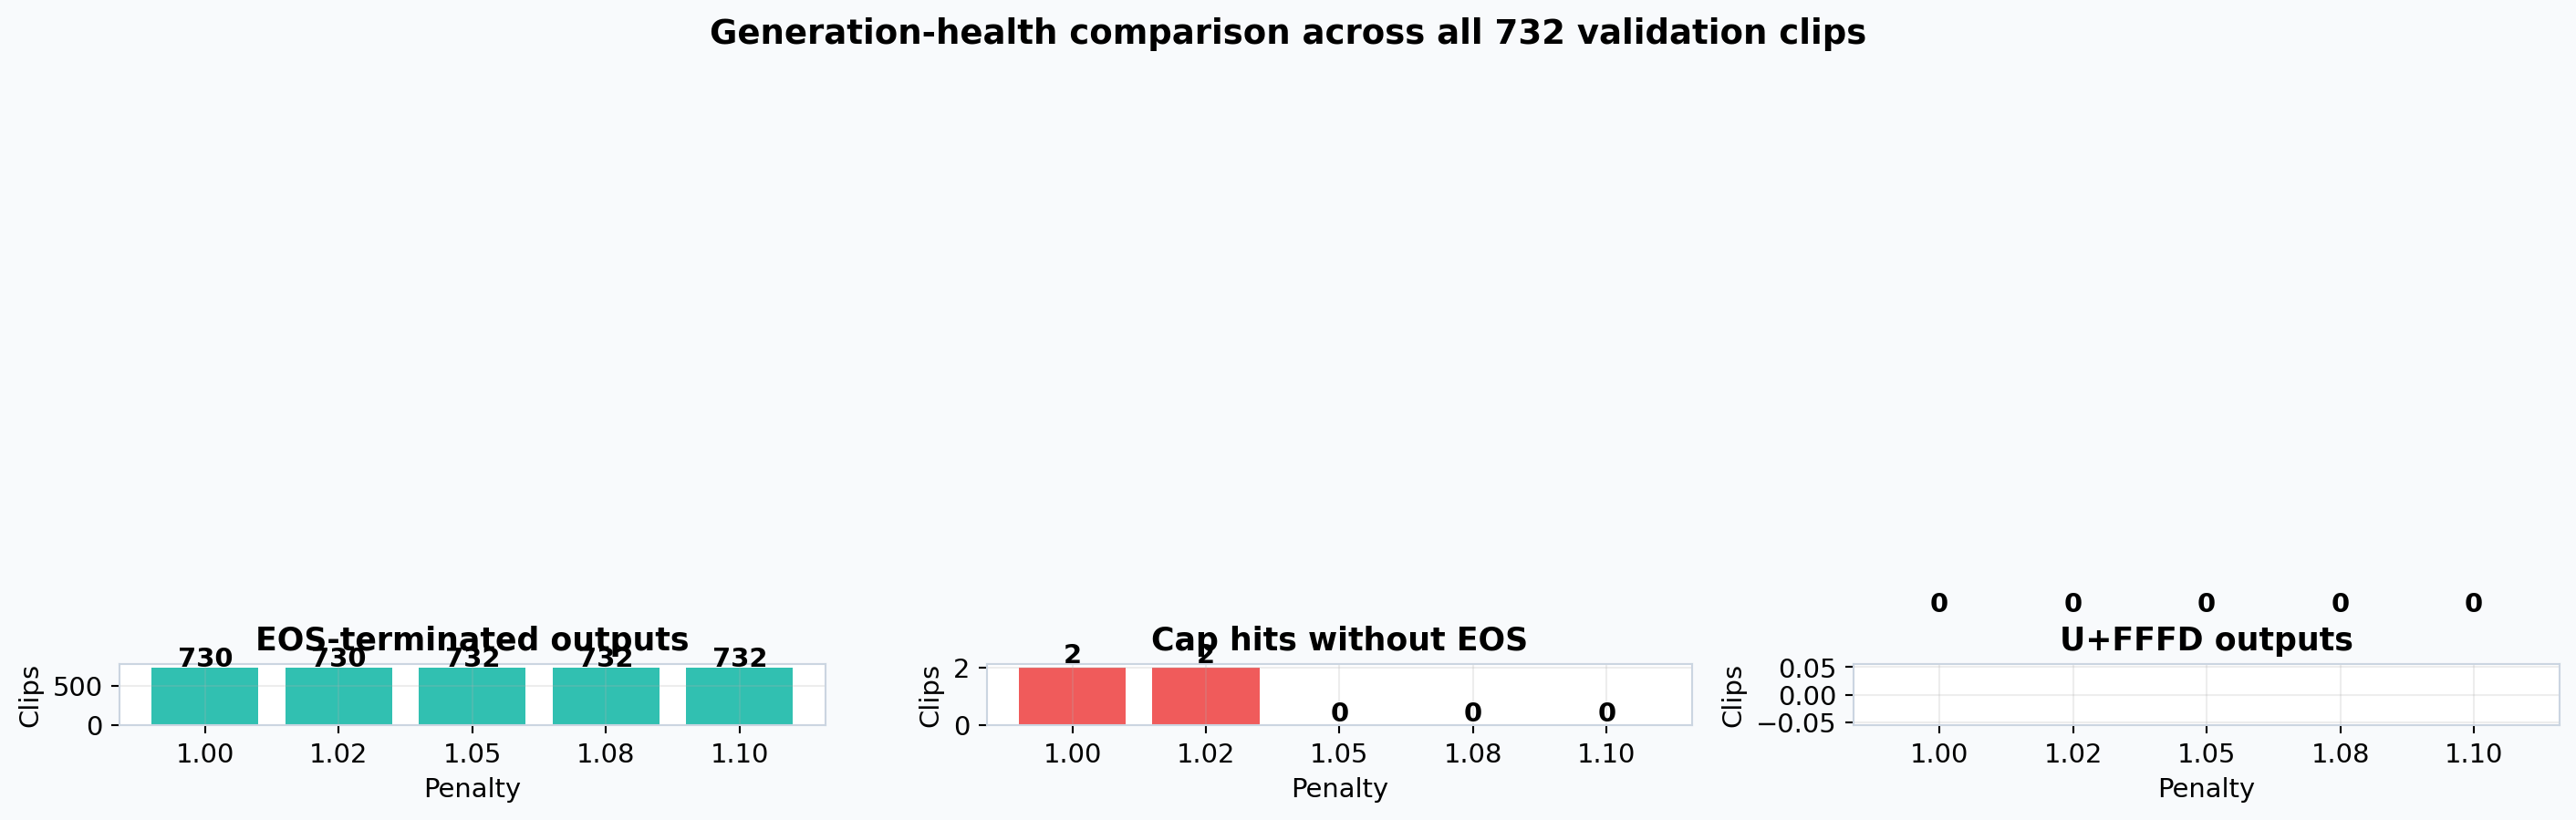

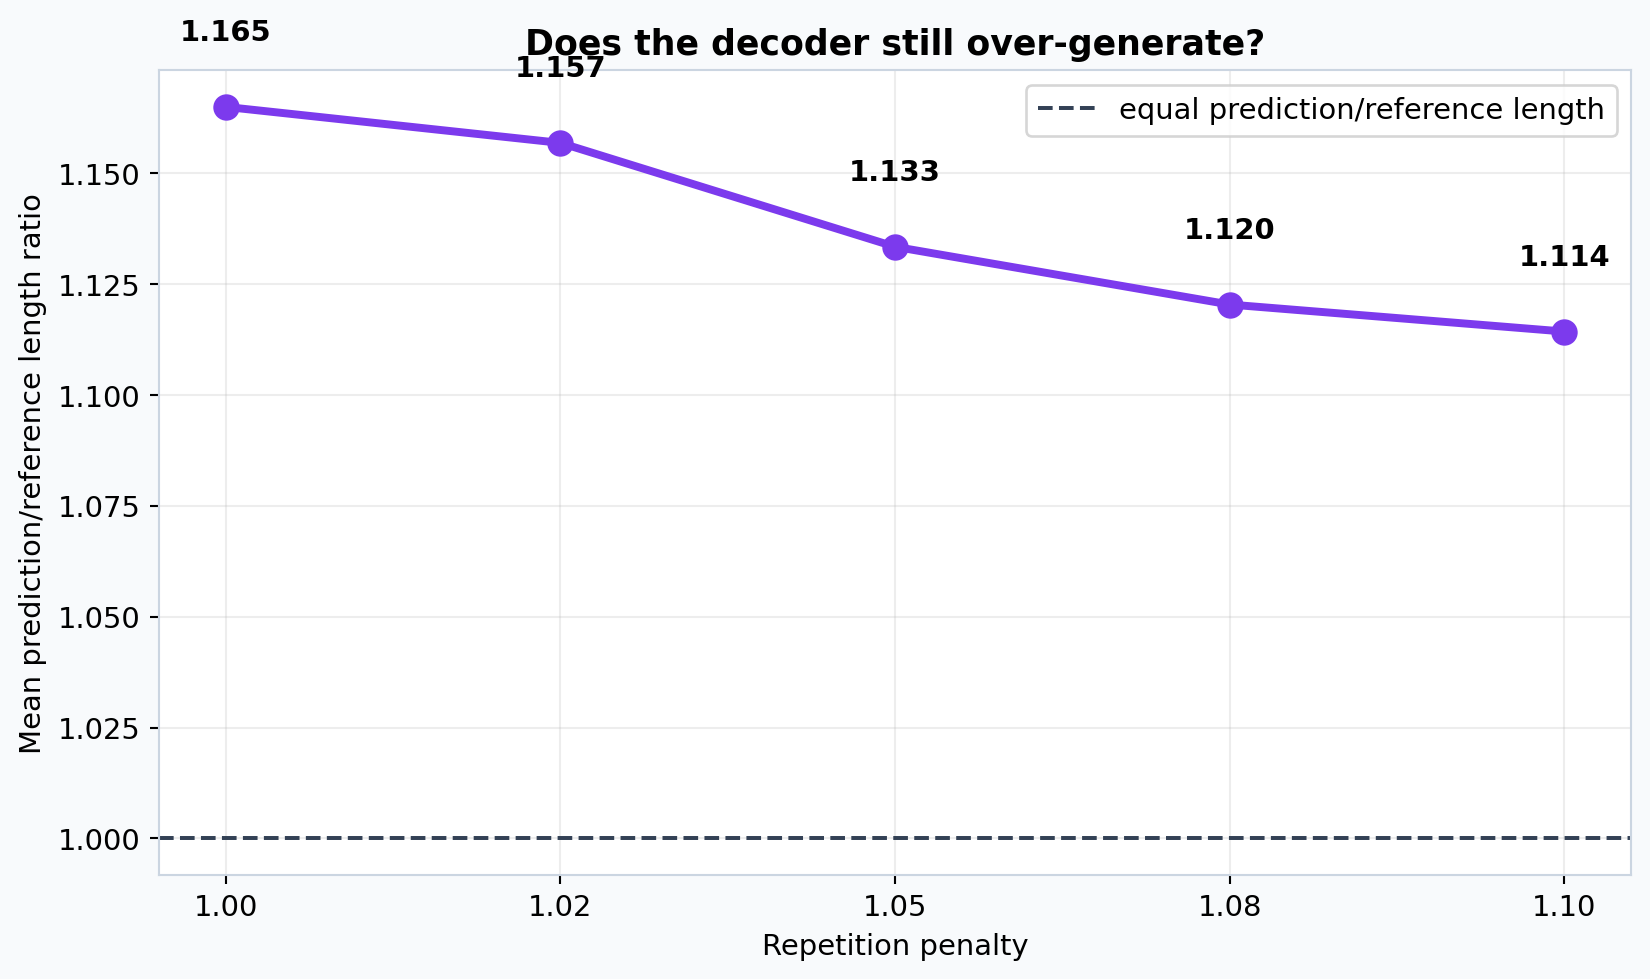

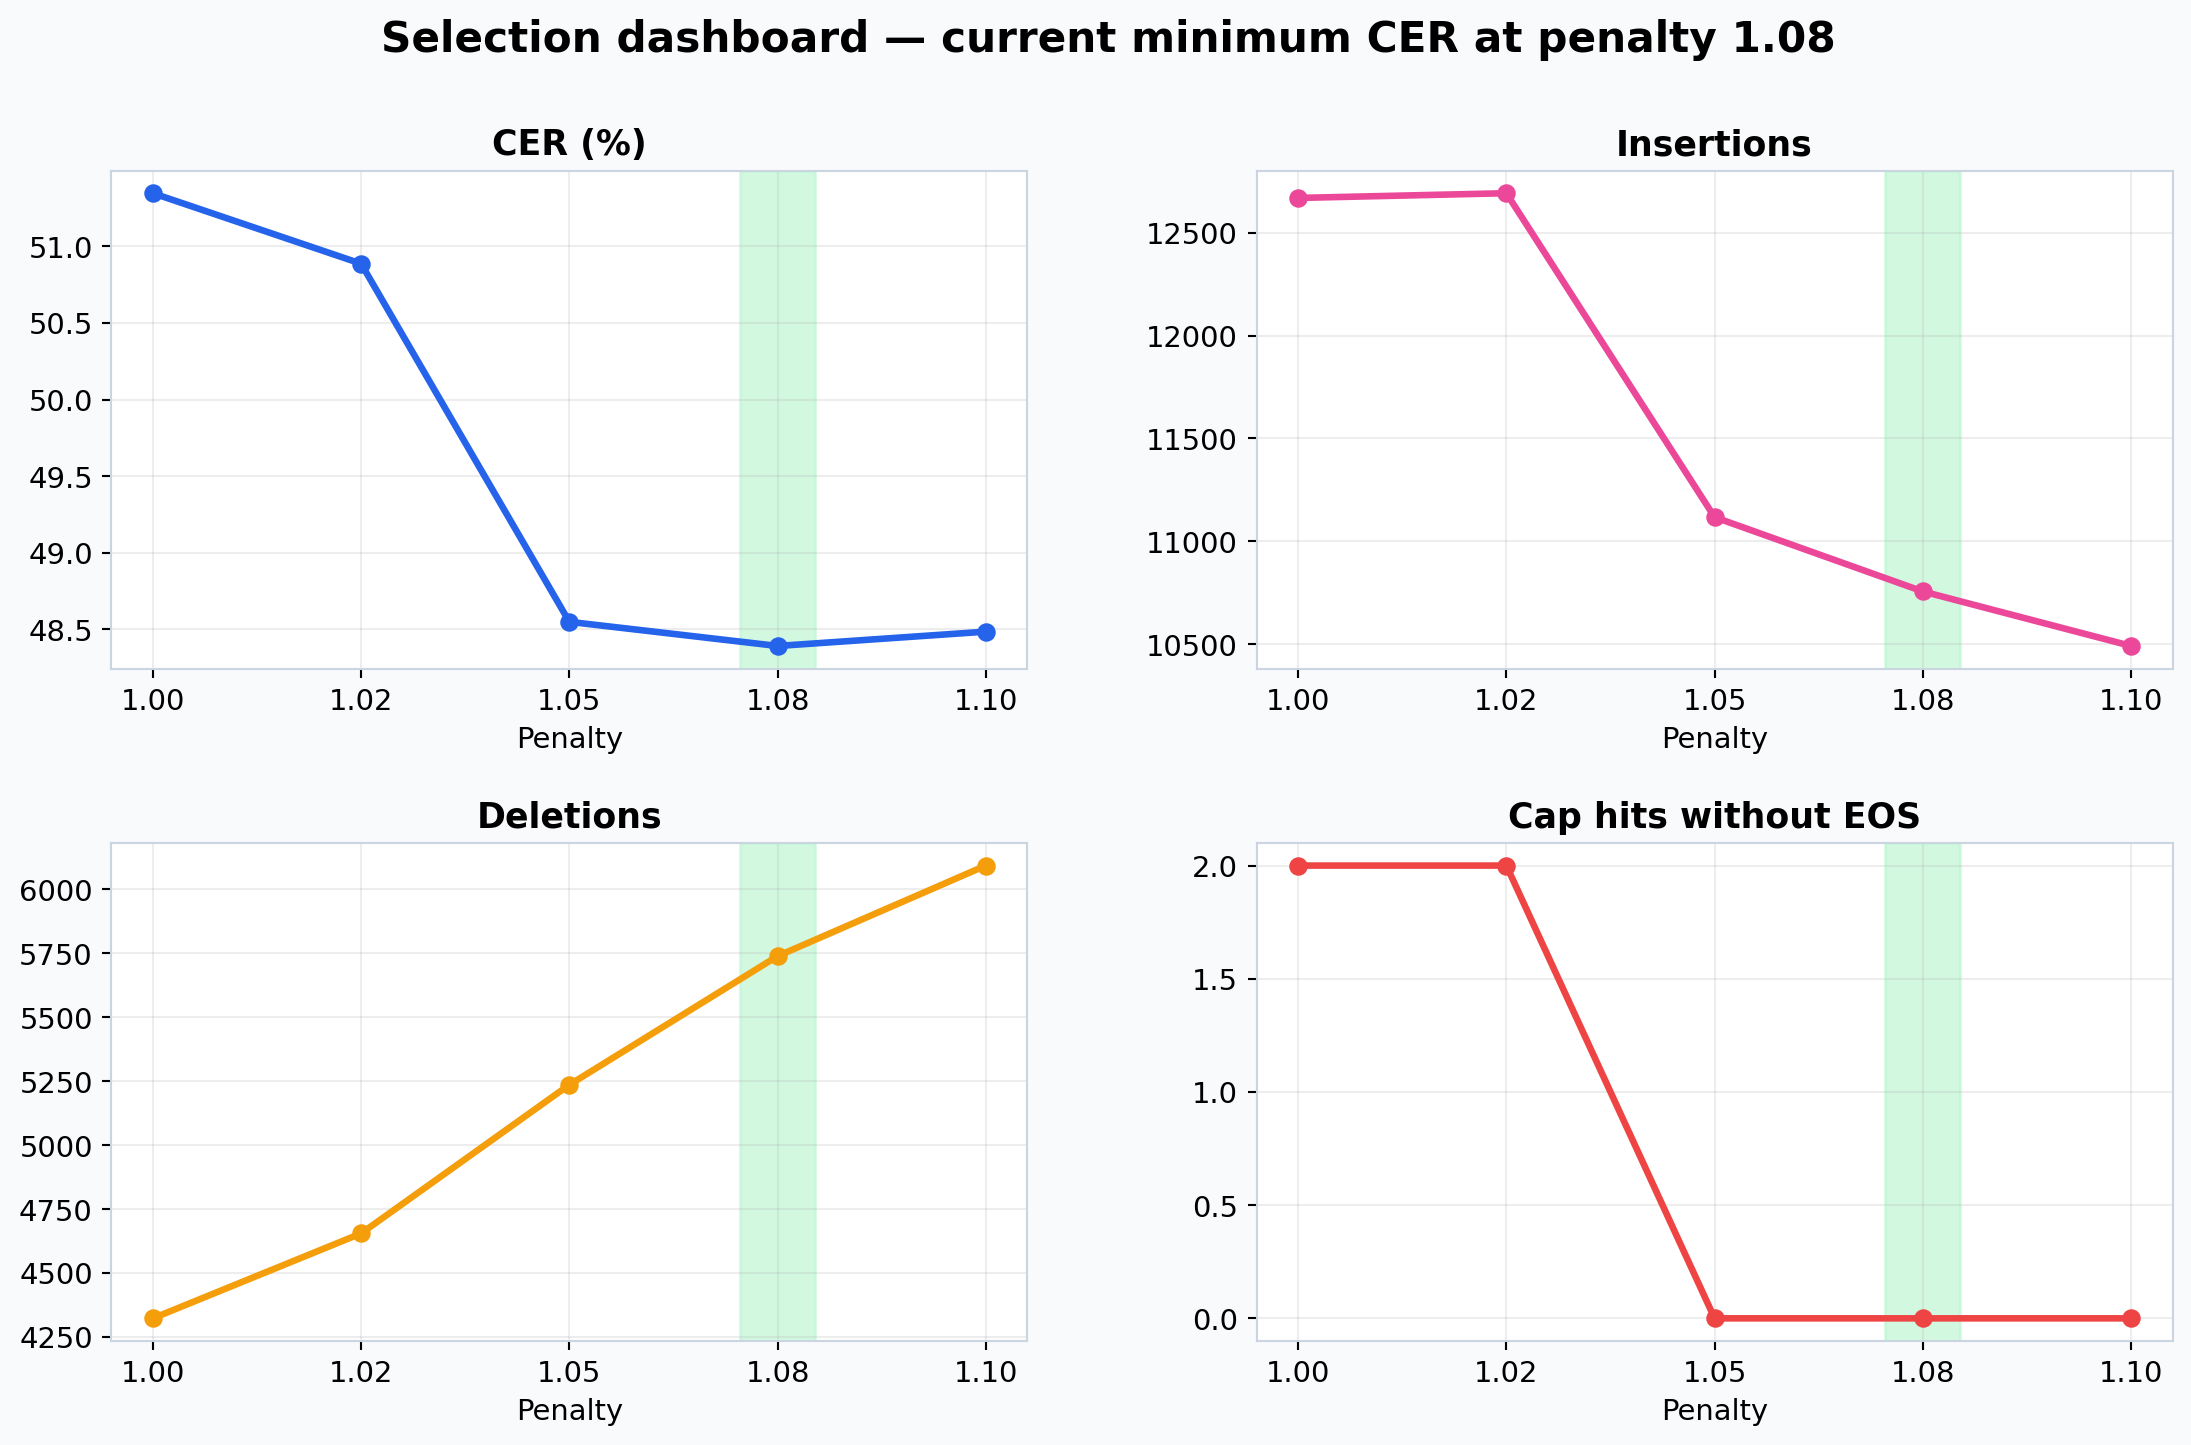

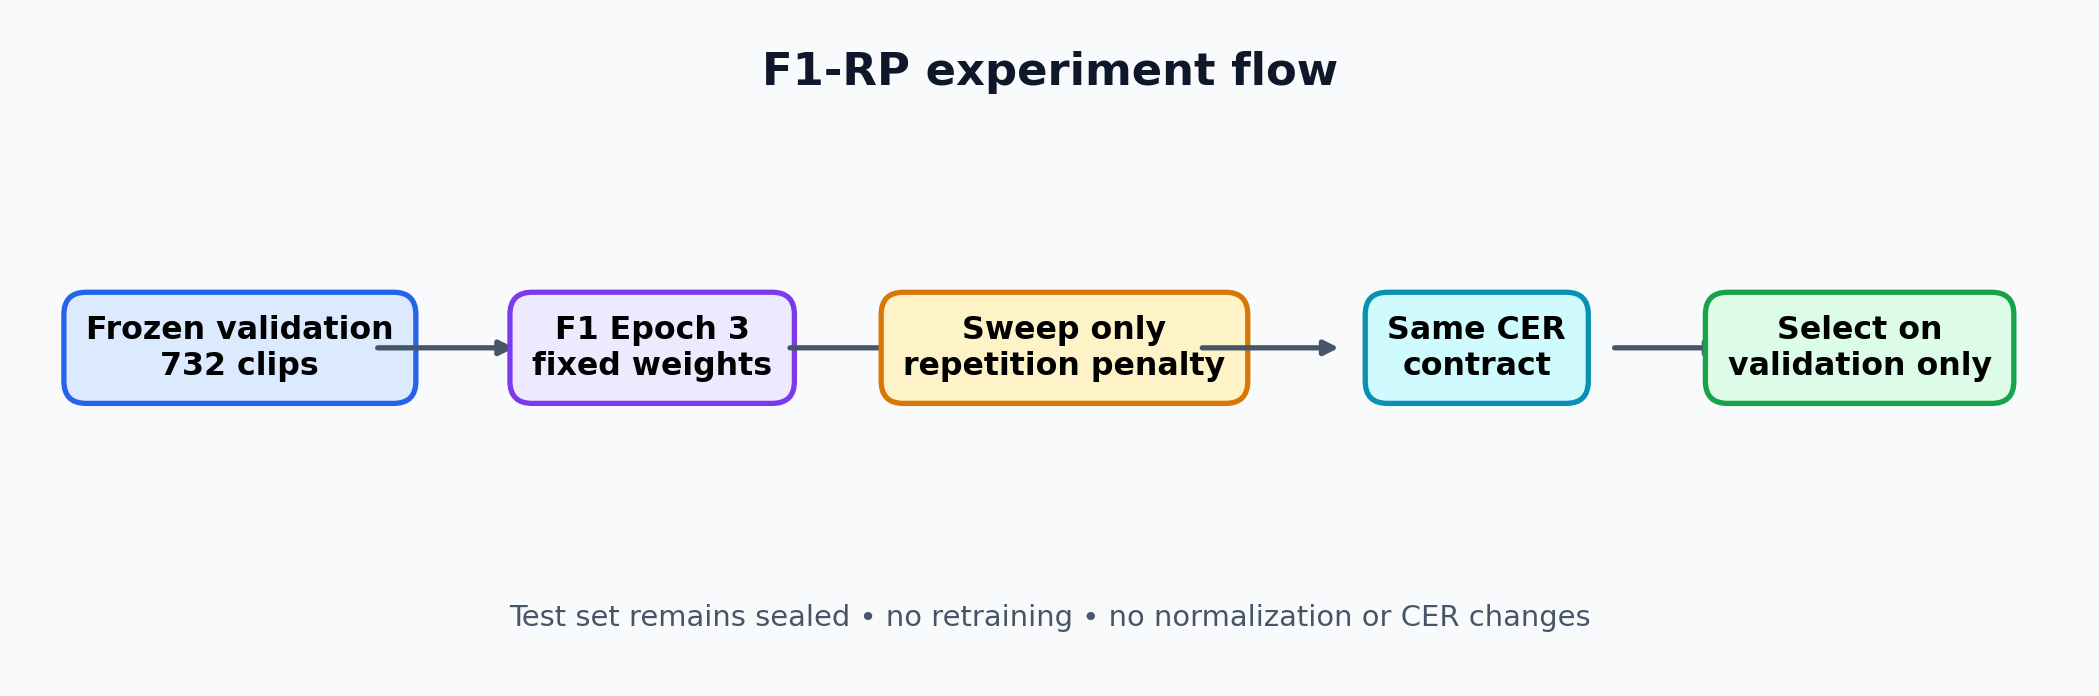

01_cer_comparison.png
02_edit_counts_grouped.png
03_error_composition_percent.png
04_cer_improvement_from_baseline.png
05_generation_health.png
06_output_length_ratio.png
07_selection_dashboard.png
08_experiment_flow.png


In [2]:
# Display every privacy-safe plot published with this experiment.
plot_dir = ROOT / 'assets' / 'phase7_f1_repetition_penalty'
for plot_path in sorted(plot_dir.glob('*.png')):
    print(plot_path.name)
    display(Image(filename=str(plot_path)))

## Interpretation

The sweep shows that mild repetition penalties reduce insertions and output over-generation. Penalty `1.10` suppresses insertions slightly more than `1.08`, but increases deletions; `1.08` gives the lowest total CER. The difference between `1.05` and `1.08` is small, so the final choice must remain validation-based until the sealed test evaluation.